# A5 – Relato y recomendaciones cuantificadas

## El relato en una frase

**RetailVenture no está empeorando: lleva dos años perdiendo margen siempre en los mismos tres sitios.** Esos sitios son el descuento online, las devoluciones de dos categorías y un marketing que no se puede medir.

- **Inicio (situación actual):** la gerencia cree que el margen cae. Los datos dicen otra cosa: el margen bruto, el ticket y las devoluciones están estables desde 2023 (sección 1). Lo único que cae es la conversión *registrada* de las campañas.
- **Nudo (hallazgos):**
  - el canal online regala el doble de descuento y el descuento no trae más ventas (A2);
  - Ropa y Electrónica devuelven mucho más que el resto (A3);
  - los clientes que se van son sobre todo compradores esporádicos (A3);
  - no hay forma de saber si las campañas generan ventas (A4).
- **Desenlace (recomendaciones):** una tabla que une cada pérdida con lo que se puede hacer (sección 2) y cuatro medidas. Una trae dinero (R1), dos sirven para medir antes de gastar (R2 y R3) y una es de higiene (R4). Cada una con su supuesto y su rango (secciones 3 a 7).

## Cómo cuantificamos

El enunciado pide cuantificar al menos tres recomendaciones con la forma: *"Si hacemos X, esperamos un incremento/reducción de Y% en Z métrica, equivalente a [monto] en ingresos"*.

Cada recomendación sale de un hallazgo de A2, A3 o A4. Para cada una damos:
- el hallazgo en el que se apoya,
- el supuesto del que depende la cifra (y por qué es razonable),
- un escenario central y un rango (escenarios prudente y optimista),
- el riesgo principal y, cuando hay inversión, el costo máximo con el que sigue siendo rentable.

Las cifras son **anuales con base 2024** (el último año completo), salvo R3, que actúa una sola vez sobre los clientes en riesgo de hoy. Montos en unidades monetarias (u. m.). Las decisiones están en `DECISIONES.md` (A5.1 a A5.6).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.carga import cargar_limpio, RAIZ
from src.powerbi import SALIDA, guardar

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"]
cam = d["campanas_marketing"]
dev = d["devoluciones"]
anio = trx[trx.fecha >= "2024-01-01"]
VENTAS, MARGEN = anio.monto_neto.sum(), anio.margen_bruto.sum()
FIG = RAIZ / "figures"

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

def signo(x):
    return ("+" if x >= 0 else "−") + miles(abs(x))

print(f"Base 2024: ventas {miles(VENTAS)} | margen bruto {miles(MARGEN)} ({MARGEN / VENTAS:.1%})")
recomendaciones = []

Base 2024: ventas 8.684.581 | margen bruto 2.162.763 (24.9%)


## 1. Situación inicial: qué cambia y qué no

Las cuatro cifras que preocupan a la gerencia, trimestre a trimestre, en un solo gráfico. Para poder ponerlas juntas, cada una se expresa como índice: el primer trimestre de 2023 vale 100. Las devoluciones se miden por fecha de compra (A1.8).

trimestre                2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4
margen bruto %             24.6    24.7    24.7    24.6    25.4    24.9    24.7    24.7
ticket promedio           350.4   344.0   363.2   347.7   340.4   341.7   348.9   347.0
devoluciones %             13.2    13.6    13.0    13.8    13.3    13.3    13.8    13.5
conversión registrada %    11.3    12.3    11.2    10.2     7.9     6.8     7.1     5.6


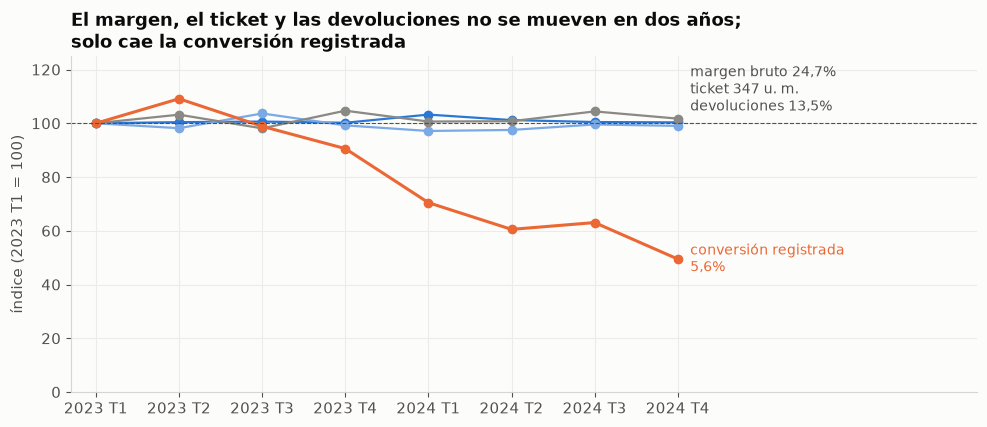

In [2]:
q = trx.groupby("trimestre").agg(ventas=("monto_neto", "sum"), margen=("margen_bruto", "sum"),
                                ticket=("monto_neto", "mean"), devolucion=("devuelta", "mean"))
situacion = pd.DataFrame({
    "margen bruto %": 100 * q.margen / q.ventas,
    "ticket promedio": q.ticket,
    "devoluciones %": 100 * q.devolucion,
    "conversión registrada %": 100 * cam.groupby(cam.fecha_envio.dt.to_period("Q").astype(str)).convertido.mean(),
})
situacion.index.name = "trimestre"
print(situacion.round(1).T.to_string())
indice = 100 * situacion / situacion.iloc[0]
largo = indice.reset_index().melt(id_vars="trimestre", var_name="métrica", value_name="índice (2023 T1 = 100)")
largo["valor"] = situacion.reset_index().melt(id_vars="trimestre").value
guardar(largo, "resultado_a5_situacion_trimestre")

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(indice))
for col, color in zip(indice.columns, [AZUL, "#7aa9e6", GRIS, NARANJA]):
    ax.plot(x, indice[col], marker="o", color=color, lw=2.2 if color == NARANJA else 1.6)
u = situacion.iloc[-1]
ax.text(x[-1] + 0.15, 103, f"margen bruto {u['margen bruto %']:.1f}%\nticket {u['ticket promedio']:.0f} UM\ndevoluciones {u['devoluciones %']:.1f}%".replace(".", ",").replace("UM", "u. m."),
        va="bottom", color=TEXTO_2, fontsize=10)
ax.text(x[-1] + 0.15, indice.iloc[-1, -1], f"conversión registrada\n{u['conversión registrada %']:.1f}%".replace(".", ","), va="center", color=NARANJA, fontsize=10)
ax.axhline(100, color=TEXTO_2, lw=0.8, ls="--")
ax.set_xticks(x, [t.replace("Q", " T") for t in indice.index])
ax.set_xlim(-0.3, len(x) + 2.6)
ax.set_ylim(0, 125)
ax.set_ylabel("índice (2023 T1 = 100)")
ax.set_title("El margen, el ticket y las devoluciones no se mueven en dos años;\nsolo cae la conversión registrada")
fig.tight_layout()
fig.savefig(FIG / "a5_situacion_inicial.png", dpi=150)
plt.show()

**El inicio del relato:** en el índice, el margen bruto, el ticket y las devoluciones se mueven en una franja de ±5% alrededor de 100. La conversión registrada cae a la mitad. Es decir:
- **Lo que el enunciado dice y los datos confirman:** las devoluciones están en torno al 14% (medidas en dinero) y la conversión registrada se cayó a la mitad.
- **Lo que no confirman:** el ticket no cae un 8% y el margen no está bajo una "presión creciente". Hay un **nivel** de pérdidas que se repite cada trimestre.
- La caída de la conversión registrada no se refleja en las compras (A4).

## 2. R1. Alinear el descuento online con el de tienda y app (piloto)

**Hallazgos (A2.5):**
- Online da el doble de descuento que la tienda y la app (7,5% contra 3,7%) y es el canal con menor margen.
- Los descuentos no generan volumen: con más descuento se compran las mismas unidades por compra.
- Una compra con más descuento no hace volver antes al cliente. Comparando las compras de cada cliente consigo mismo, la recompra a 90 días cambia +0,0 puntos por cada 10 de descuento (IC 95%: −0,6 a +0,7); solo online, +1,0 (IC 95%: −0,2 a +2,1).
- Entre productos y meses no hay promociones: el descuento cambia venta a venta. Entre clientes no es igual: los Premium reciben menos.

**Qué proponemos:**
- que el descuento medio online sea el mismo que en tienda y app, con un tope por venta;
- que, en todos los canales, ninguna venta se haga por debajo del costo.

Se aplica primero como **piloto** en una parte de los productos online, comparando con el resto.

**Qué recibe Electrónica:** es la categoría con menos margen y la que más descuento online tiene, así que recibe casi la mitad del beneficio de R1. Esto es porque es el 44% de las ventas, no por una regla propia. Para sus devoluciones, la medida es el diagnóstico de R2.

**Supuesto:** las ventas no cambian, porque el descuento no mueve ni las unidades ni la recompra (A2.5). **El riesgo:** solo vemos las ventas que ocurrieron; si con menos descuento alguien deja de comprar online, no lo habríamos visto. Por eso es un piloto, y por eso damos una tabla de qué pasa si online pierde ventas.

**Escenarios:** central = online iguala a tienda y app; prudente = se cierra la mitad de la brecha.

Descuento medio 2024: online 7.5% | tienda y app 3.7%
Margen bruto 2024: online 22.7% | tienda y app 26.2%
Online regala 274.235 en descuentos (57% del total)



Tope por venta online que iguala el descuento medio: 4.7% (afecta a 58% de las ventas online)
Ventas bajo costo en tienda y app (2024): 147, pérdida 5.093
Ingreso y margen extra al año: central 146.161 | prudente 77.325 | de Electrónica: 48%
Margen bruto online 2024: 740.822 -> 881.890 (+19.0%)
Compensa mientras online no pierda más del 16% de sus ventas

R1 si online pierde ventas:
online pierde margen extra al año
           0%             146.161
           5%             102.066
          10%              57.972
          16%               5.093
Peor caso de la recompra: bajar 3.8 puntos el descuento online cambia la recompra en -0.79 puntos, un 1.2% menos de recompras. Muy lejos del 16% que haría falta para que R1 no compense.


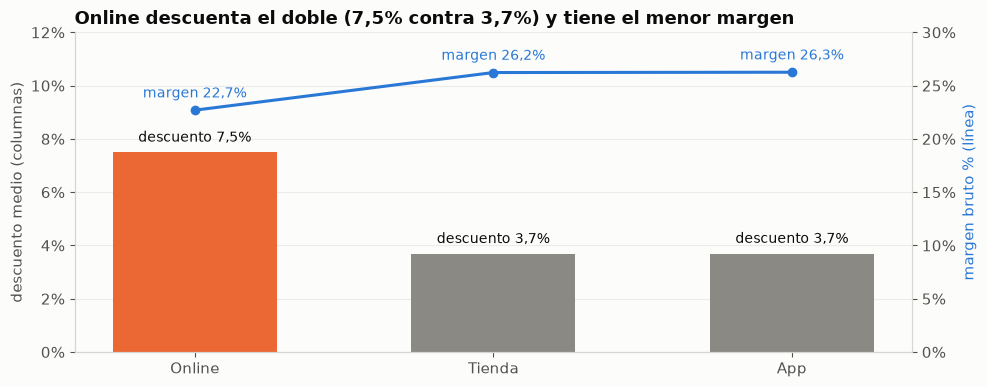

In [3]:
online = anio[anio.canal == "online"]
resto = anio[anio.canal != "online"]
d_resto = resto.descuento.mean()
bruto = online.cantidad * online.precio_unitario          # venta a precio de lista
print(f"Descuento medio 2024: online {online.descuento.mean():.1%} | tienda y app {d_resto:.1%}")
print(f"Margen bruto 2024: online {online.margen_bruto.sum() / online.monto_neto.sum():.1%} | "
      f"tienda y app {resto.margen_bruto.sum() / resto.monto_neto.sum():.1%}")
print(f"Online regala {miles(online.costo_descuento.sum())} en descuentos ({online.costo_descuento.sum() / anio.costo_descuento.sum():.0%} del total)")

def recorte(meta):
    # cada venta online con más descuento que 'meta' baja a 'meta'
    nuevo = np.minimum(online.descuento, meta)
    return ((online.descuento - nuevo) * bruto).sum()

# Buscamos el tope que deja el descuento medio online igual al de tienda y app
topes = np.linspace(0, 0.35, 701)
medias = [np.minimum(online.descuento, t).mean() for t in topes]
tope = topes[np.argmin(np.abs(np.array(medias) - d_resto))]
central_online = recorte(tope)
prudente_online = recorte(topes[np.argmin(np.abs(np.array(medias) - (online.descuento.mean() + d_resto) / 2))])
nuevo = np.minimum(online.descuento, tope)
assert ((bruto * (1 - nuevo) - online.costo_total) >= 0).all()   # con el tope, ninguna venta online queda bajo costo

# Ventas bajo costo en tienda y app: lo que se deja de perder si ninguna baja del costo
bajo_costo = -resto.loc[resto.bajo_costo, "margen_bruto"].sum()
central, prudente = central_online + bajo_costo, prudente_online + bajo_costo
de_electronica = (((online.descuento - nuevo) * bruto)[online.categoria == "Electrónica"].sum()
                  + -resto.loc[resto.bajo_costo & (resto.categoria == "Electrónica"), "margen_bruto"].sum())
print(f"\nTope por venta online que iguala el descuento medio: {tope:.1%} (afecta a {(online.descuento > tope).mean():.0%} de las ventas online)")
print(f"Ventas bajo costo en tienda y app (2024): {resto.bajo_costo.sum()}, pérdida {miles(bajo_costo)}")
print(f"Ingreso y margen extra al año: central {miles(central)} | prudente {miles(prudente)} | de Electrónica: {de_electronica / central:.0%}")

margen_online = online.margen_bruto.sum()
perdida_max = central_online / (margen_online + central_online)
print(f"Margen bruto online 2024: {miles(margen_online)} -> {miles(margen_online + central_online)} (+{central_online / margen_online:.1%})")
print(f"Compensa mientras online no pierda más del {perdida_max:.0%} de sus ventas")

# ¿Y si online pierde ventas? Margen neto de R1 según cuánto caigan las ventas online
sens_r1 = pd.DataFrame({"online pierde": [0, 0.05, 0.10, perdida_max]})
sens_r1["margen extra al año"] = (margen_online + central_online) * (1 - sens_r1["online pierde"]) - margen_online + bajo_costo
print("\nR1 si online pierde ventas:")
print(sens_r1.assign(**{"online pierde": (100 * sens_r1["online pierde"]).round(0).astype(int).astype(str) + "%",
                        "margen extra al año": sens_r1["margen extra al año"].map(miles)}).to_string(index=False))
# El peor caso compatible con los datos: si el descuento ayudara a volver tanto como permite la cota ALTA del IC online (A2.5),
# bajarlo quitaría recompras. +2,1 puntos de recompra a 90 días por cada 10 puntos de descuento
peor_por_10 = 2.08
baja = online.descuento.mean() - np.minimum(online.descuento, tope).mean()
recompra_online = 0.68
cambio = -peor_por_10 * baja * 10
print(f"Peor caso de la recompra: bajar {100 * baja:.1f} puntos el descuento online cambia la recompra en "
      f"{cambio:+.2f} puntos, un {abs(cambio) / (100 * recompra_online):.1%} menos de recompras. "
      f"Muy lejos del {perdida_max:.0%} que haría falta para que R1 no compense.")

recomendaciones.append(["R1", "Piloto: tope de " + f"{100 * tope:.1f}".replace(".", ",") + "% al descuento online y ninguna venta bajo costo",
                        "margen bruto total", central / MARGEN, central, prudente, central, central])

# Gráfico para el dashboard (un solo gráfico combinado): descuento medio en columnas y margen bruto % en línea, por canal
c = anio.groupby("canal").agg(descuento=("descuento", "mean"), ventas=("monto_neto", "sum"), margen=("margen_bruto", "sum"))
c = c.assign(margen_pct=100 * c.margen / c.ventas, descuento=100 * c.descuento).reindex(["online", "tienda_fisica", "app_movil"])
fig, ax = plt.subplots(figsize=(10, 4))
nombres = ["Online", "Tienda", "App"]
x = np.arange(3)
ax.bar(x, c.descuento, color=[NARANJA, GRIS, GRIS], width=0.55, label="descuento medio")
for i, v in enumerate(c.descuento):
    ax.text(i, v + 0.4, f"descuento {v:.1f}%".replace(".", ","), ha="center", fontsize=10)
ax2 = ax.twinx()
ax2.plot(x, c.margen_pct, color=AZUL, marker="o", lw=2.2)
for i, v in enumerate(c.margen_pct):
    ax2.text(i, v + 1.2, f"margen {v:.1f}%".replace(".", ","), color=AZUL, fontsize=10, ha="center")
ax.set_xticks(x, nombres)
ax.set_ylim(0, 12)
ax2.set_ylim(0, 30)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax2.spines["right"].set_visible(True)
ax.set_ylabel("descuento medio (columnas)")
ax2.set_ylabel("margen bruto % (línea)", color=AZUL)
ax.grid(axis="x", visible=False)
ax2.grid(False)
ax.set_title(f"Online descuenta el doble ({c.descuento['online']:.1f}% contra {c.descuento['tienda_fisica']:.1f}%) y tiene el menor margen".replace(".", ","))
fig.tight_layout()
fig.savefig(FIG / "a5_online_descuento.png", dpi=150)
plt.show()

## 3. R2. Guía de tallas en Ropa, y buscar la causa del exceso de Electrónica

**Hallazgos (A3.1):**
- Solo dos categorías devuelven más de lo normal: Ropa y Calzado (21,8%) y Electrónica (17,7%), contra 10,3% del resto.
- En Ropa, una parte del exceso tiene una causa clara: la talla incorrecta, un motivo que solo existe en esa categoría.
- En Electrónica, el reparto de motivos es igual al del resto y ningún producto tiene más defectuosos de lo normal. Los datos no señalan una causa.

**Qué proponemos:**
- **Ropa:** guía de tallas y tabla de medidas en cada ficha. Es la parte que se puede cuantificar.
- **Electrónica (y el resto del exceso de Ropa):** antes de invertir, un diagnóstico. Por ejemplo, revisar una muestra de devoluciones y preguntar al cliente. Damos lo que está en juego como **techo**, no como estimación.

**Supuesto:** la guía evita una parte de las devoluciones por talla. No sabemos cuánta, así que damos escenarios de 25%, 50% y 75%. Cada devolución evitada es una venta que no se reembolsa. Como una prenda de talla equivocada se revende, se gana su margen (A2.1).

In [4]:
ropa = anio[anio.categoria == "Ropa_y_Calzado"]
talla = ropa[ropa.devuelta & (ropa.motivo_devolucion == "Talla_incorrecta")]
talla_ingreso, talla_margen = talla.monto_neto.sum(), (talla.margen_bruto - talla.margen_neto).sum()
print(f"Devoluciones por talla en 2024: {len(talla)} de {ropa.devuelta.sum()} devoluciones de Ropa "
      f"({len(talla) / ropa.devuelta.sum():.0%}) | {miles(talla_ingreso)} reembolsados, {miles(talla_margen)} de margen")

esc = {p: (p * talla_ingreso, p * talla_margen) for p in [0.25, 0.5, 0.75]}
for p, (i, m) in esc.items():
    print(f"  evitar el {p:.0%} de las devoluciones por talla: +{miles(i)} en ingresos, +{miles(m)} de margen")
dev_ropa = ropa[ropa.devuelta].monto_neto.sum()
print(f"Escenario central (50%): las devoluciones de Ropa bajan un {esc[0.5][0] / dev_ropa:.1%}")
print(f"Costo máximo de la guía para que compense: {miles(esc[0.5][1])} al año")

# Techo: todo el exceso de Ropa y Electrónica sobre la tasa del resto (misma base que A3.5)
DOS = ["Ropa_y_Calzado", "Electrónica"]
tasa_resto = anio[~anio.categoria.isin(DOS)].devuelta.mean()
techo_ingreso = techo_margen = techo_margen_prov = 0
for c in DOS:
    x = anio[anio.categoria == c]
    fraccion = 1 - tasa_resto / x.devuelta.mean()
    dv = x[x.devuelta]
    techo_ingreso += dv.monto_neto.sum() * fraccion
    techo_margen += (dv.margen_bruto - dv.margen_neto).sum() * fraccion
    techo_margen_prov += dv.margen_bruto.sum() * fraccion
print(f"\nTecho (todo el exceso de Ropa y Electrónica, 2024): {miles(techo_ingreso)} en ingresos; "
      f"margen de {miles(techo_margen_prov)} a {miles(techo_margen)} según quién asuma los defectuosos")
# El techo es el doble de la cifra a 6 meses de A3.5 (misma base)
a3 = pd.read_csv(SALIDA / "resultado_a3_impacto_6_meses.csv", index_col=0)
assert abs(a3.loc["Devoluciones por encima de lo normal (Ropa y Electrónica)", "ingresos"] * 2 - techo_ingreso) < 1

recomendaciones.append(["R2", "Guía de tallas en Ropa (y diagnóstico de las devoluciones de Electrónica)",
                        "devoluciones de Ropa", -esc[0.5][0] / dev_ropa, esc[0.5][0], esc[0.25][0], esc[0.75][0], esc[0.5][1]])

Devoluciones por talla en 2024: 140 de 904 devoluciones de Ropa (15%) | 26.733 reembolsados, 10.599 de margen
  evitar el 25% de las devoluciones por talla: +6.683 en ingresos, +2.650 de margen
  evitar el 50% de las devoluciones por talla: +13.367 en ingresos, +5.300 de margen
  evitar el 75% de las devoluciones por talla: +20.050 en ingresos, +7.949 de margen
Escenario central (50%): las devoluciones de Ropa bajan un 8.3%
Costo máximo de la guía para que compense: 5.300 al año

Techo (todo el exceso de Ropa y Electrónica, 2024): 370.164 en ingresos; margen de 70.467 a 161.647 según quién asuma los defectuosos


## 4. R3. Reactivar a los clientes recurrentes en riesgo, con grupo de control

**Hallazgos:**
- **A3.4:** hay 1.388 clientes recurrentes (2 o más compras) que llevan más de 180 días sin comprar. Si no vuelven, la empresa deja de ingresar unas 232.500 u. m. en los próximos 6 meses. El 74% de ese valor está en clientes del segmento Esporádico.
- **A4.3:** no hay pruebas de que las campañas actuales generen compras.

**Qué proponemos:** una campaña de reactivación para estos clientes, que se pueden identificar hoy con sus compras y su última fecha de compra, **dejando un grupo de control**: un 20% elegido al azar que no la recibe. Así, por primera vez, se mide si una campaña genera ventas comparando con quien no la recibió.

**Supuesto:** no sabemos cuánto recupera una campaña, y los datos actuales no permiten estimarlo. Damos escenarios de 5%, 10% y 20% de los ingresos en riesgo. Es una cifra **a 6 meses y de una sola vez**: actúa sobre los clientes en riesgo de hoy, así que no se multiplica por dos para anualizarla. El valor seguro de esta recomendación es la medición.

In [5]:
riesgo_6m = a3.loc["Clientes recurrentes en riesgo que no vuelven", "ingresos"]   # notebook 03, A3.5
margen_pct = MARGEN / VENTAS
esc = {p: p * riesgo_6m for p in [0.05, 0.10, 0.20]}
for p, v in esc.items():
    print(f"  recuperar el {p:.0%} de lo que está en riesgo: +{miles(v)} en ingresos en 6 meses (+{miles(v * margen_pct)} de margen)")
print(f"Costo máximo de la campaña para que compense (escenario central): {miles(esc[0.10] * margen_pct)}")

recomendaciones.append(["R3", "Campaña de reactivación a los clientes recurrentes en riesgo, con 20% de grupo de control",
                        "ingresos de los clientes recurrentes en riesgo", 0.10, esc[0.10], esc[0.05], esc[0.20], esc[0.10] * margen_pct])

  recuperar el 5% de lo que está en riesgo: +11.367 en ingresos en 6 meses (+2.831 de margen)
  recuperar el 10% de lo que está en riesgo: +22.734 en ingresos en 6 meses (+5.662 de margen)
  recuperar el 20% de lo que está en riesgo: +45.468 en ingresos en 6 meses (+11.323 de margen)
Costo máximo de la campaña para que compense (escenario central): 5.662


## 5. R4. Limitar el descuento de las campañas al 5%

**Hallazgo (A4.5):**
- Aunque aceptemos la marca de conversión, las conversiones extra que trae el descuento no pagan el descuento que se regala a todas las conversiones. Solo el 5% se paga solo; de 10% en adelante, cada envío pierde margen.
- Según las compras reales, el descuento no cambia nada.

**Qué proponemos:** que ninguna campaña ofrezca más de 5% de descuento.

**Supuesto:** usamos la lectura más favorable al descuento, la marca de conversión de A4.
- Cada conversión se valora con el ticket y el margen de las compras coincidentes (355 u. m. y 23,4%). Es casi el ticket de cualquier compra (344–351), así que no depende de que esas compras sean coincidencias.
- Con la lectura de las compras reales, el ahorro sería mayor, porque todo el descuento de campaña sería costo sin retorno.
- La conversión registrada bajaría, y hay que avisarlo para que no se lea como un fracaso.

In [6]:
pares = cam[cam.conversion_respaldada][["campana_id", "cliente_id", "fecha_envio"]].merge(
    trx[["cliente_id", "fecha", "monto_neto", "margen_bruto"]], on="cliente_id")
pares = pares[(pares.fecha - pares.fecha_envio).dt.days.between(0, 30)].sort_values("fecha").drop_duplicates("campana_id")
ticket, mpct = pares.monto_neto.mean(), pares.margen_bruto.sum() / pares.monto_neto.sum()
conv = cam.groupby("descuento_ofrecido").convertido.mean()
neto = (conv - conv[0]) * ticket * mpct - conv * conv.index * ticket       # margen por envío frente a 0% de descuento
envios = cam[cam.fecha_envio.dt.year == 2024].descuento_ofrecido.value_counts()
actual = (neto * envios).sum()
con_tope = neto[0.05] * envios[envios.index >= 0.05].sum()
ahorro = con_tope - actual
print(f"Ticket de las compras coincidentes: {ticket:.0f} | de todas las compras 2024: {anio.monto_neto.mean():.0f}")
print("Margen por envío frente a no dar descuento (según la marca):", neto.round(2).to_dict())
print(f"Envíos 2024 con más de 5%: {envios[envios.index > 0.05].sum()} de {envios.sum()}")
print(f"Margen de las campañas 2024: actual {miles(actual)} | con tope de 5%: {miles(con_tope)} | diferencia +{miles(ahorro)}")
regalado = (cam[(cam.fecha_envio.dt.year == 2024)].pipe(lambda c: (c.convertido * c.descuento_ofrecido).sum()) * ticket)
regalado_5 = (cam[(cam.fecha_envio.dt.year == 2024)].pipe(lambda c: (c.descuento_ofrecido.clip(upper=0.05) > 0).mul(conv[0.05]).sum()) * 0.05 * ticket)
print(f"Descuento regalado en campañas 2024: {miles(regalado)} -> {miles(regalado_5)} con el tope")
print(f"Conversión registrada esperada: cae de {conv[conv.index > 0.05].mean():.1%} a {conv[0.05]:.1%} en los envíos que hoy tienen más de 5%")

# Ingresos registrados (según la marca): conversiones × ticket × (1 − descuento). Con menos descuento hay menos conversiones.
altos = envios[envios.index > 0.05]
ingresos_cambio = sum(n * (conv[0.05] * ticket * 0.95 - conv[k] * ticket * (1 - k)) for k, n in altos.items())
print(f"Ingresos registrados por campañas: {'+' if ingresos_cambio > 0 else '−'}{miles(abs(ingresos_cambio))} al año (menos conversiones)")

recomendaciones.append(["R4", "Tope de 5% al descuento de las campañas", "descuento regalado en campañas",
                        -(regalado - regalado_5) / regalado, ingresos_cambio, ingresos_cambio, ingresos_cambio, ahorro])

Ticket de las compras coincidentes: 355 | de todas las compras 2024: 344
Margen por envío frente a no dar descuento (según la marca): {0.0: 0.0, 0.05: 0.25, 0.1: -0.08, 0.15: -1.07, 0.2: -2.88, 0.25: -4.9}
Envíos 2024 con más de 5%: 2914 de 4452
Margen de las campañas 2024: actual -6.266 | con tope de 5%: 931 | diferencia +7.197
Descuento regalado en campañas 2024: 16.415 -> 4.507 con el tope
Conversión registrada esperada: cae de 10.6% a 6.9% en los envíos que hoy tienen más de 5%
Ingresos registrados por campañas: −21.737 al año (menos conversiones)


## 6. Resumen: las recomendaciones en el formato del enunciado

In [7]:
r = pd.DataFrame(recomendaciones, columns=["id", "qué hacemos", "métrica", "cambio en la métrica", "ingresos (central)",
                                           "desde", "hasta", "margen (central)"]).set_index("id")
r["periodo"] = ["al año", "al año", "en 6 meses, una vez", "al año"]
r["ingresos"] = ["ingresos", "ingresos", "ingresos", "ingresos registrados por campañas"]
r = r.sort_values("margen (central)", ascending=False)
for i, f in r.iterrows():
    verbo = "un incremento" if f["cambio en la métrica"] > 0 else "una reducción"
    print(f"{i}. Si hacemos «{f['qué hacemos']}», esperamos {verbo} de {abs(f['cambio en la métrica']):.1%} en {f['métrica']}, "
          f"equivalente a {signo(f['ingresos (central)'])} en {f['ingresos']} {f['periodo']}" +
          (f" (rango {miles(f['desde'])} a {miles(f['hasta'])})" if f["desde"] != f["hasta"] else "") +
          f" y {signo(f['margen (central)'])} de margen.")
anual = r.loc[r.periodo == "al año", "margen (central)"].sum()
total = r["margen (central)"].sum()
print(f"\nMargen al año (R1, R2 y R4): {miles(anual)} ({anual / MARGEN:.1%} del margen bruto de 2024); "
      f"R1 es el {r.loc['R1', 'margen (central)'] / anual:.0%}. Además, R3: {miles(r.loc['R3', 'margen (central)'])} en 6 meses, una vez.")
print(f"Aparte, el techo del exceso de devoluciones (si el diagnóstico encuentra la causa): {miles(techo_ingreso)} en ingresos al año.")
guardar(r.reset_index(), "resultado_a5_recomendaciones")

R1. Si hacemos «Piloto: tope de 4,7% al descuento online y ninguna venta bajo costo», esperamos un incremento de 6.8% en margen bruto total, equivalente a +146.161 en ingresos al año (rango 77.325 a 146.161) y +146.161 de margen.
R4. Si hacemos «Tope de 5% al descuento de las campañas», esperamos una reducción de 72.5% en descuento regalado en campañas, equivalente a −21.737 en ingresos registrados por campañas al año y +7.197 de margen.
R3. Si hacemos «Campaña de reactivación a los clientes recurrentes en riesgo, con 20% de grupo de control», esperamos un incremento de 10.0% en ingresos de los clientes recurrentes en riesgo, equivalente a +22.734 en ingresos en 6 meses, una vez (rango 11.367 a 45.468) y +5.662 de margen.
R2. Si hacemos «Guía de tallas en Ropa (y diagnóstico de las devoluciones de Electrónica)», esperamos una reducción de 8.3% en devoluciones de Ropa, equivalente a +13.367 en ingresos al año (rango 6.683 a 20.050) y +5.300 de margen.

Margen al año (R1, R2 y R4): 158.6

## 7. La tabla de pérdidas: de dónde se va el margen y qué hacemos con cada sitio

Esta tabla une A2, A3 y A4 con las recomendaciones. Para cada sitio por donde se va el margen da:
- su tamaño;
- la parte que tiene una causa concreta y se puede atacar;
- la recomendación;
- lo que recupera en el escenario central.

Todo en margen y con base 2024; la fuga de clientes, a 6 meses.

In [8]:
regalado_tienda = anio.costo_descuento.sum()
online_sobre_resto = central_online                      # lo que online regala por encima del nivel de tienda y app
dev_anio = anio[anio.devuelta]
dev_margen_bajo, dev_margen_alto = dev_anio.margen_bruto.sum(), (anio.margen_bruto - anio.margen_neto).sum()
clientes_6m = a3.loc["Clientes recurrentes en riesgo que no vuelven"]
quejas_6m = a3.loc["Aparte: quejas sin resolver (tope)"]
perdidas = pd.DataFrame([
    ["Descuentos en ventas", "al año", regalado_tienda, f"{miles(online_sobre_resto)} (online por encima de tienda y app) + {miles(bajo_costo)} (ventas bajo costo)",
     "R1 (piloto)", r.loc["R1", "margen (central)"]],
    ["Descuento de las campañas", "al año", regalado, f"{miles(regalado - regalado_5)} (todo lo que pasa de 5%)", "R4", r.loc["R4", "margen (central)"]],
    ["Devoluciones (reembolsos)", "al año", f"{miles(dev_margen_bajo)} a {miles(dev_margen_alto)}",
     f"{miles(techo_margen_prov)} a {miles(techo_margen)} por encima de lo normal; con causa conocida, {miles(talla_margen)} (talla)",
     "R2 (guía de tallas + diagnóstico)", r.loc["R2", "margen (central)"]],
    ["Clientes recurrentes que se van", "en 6 meses", f"{miles(clientes_6m['margen (bajo)'])} a {miles(clientes_6m['margen (alto)'])}",
     "desconocida: no hay forma de medir qué recupera una campaña", "R3 (con grupo de control)", r.loc["R3", "margen (central)"]],
    ["Quejas sin resolver", "en 6 meses", f"no detectable (tope {miles(quejas_6m['margen (alto)'])})", "—", "ninguna", 0],
], columns=["sitio", "periodo", "margen que se lleva", "parte atacable (margen)", "recomendación", "recupera (central)"])
perdidas["margen que se lleva"] = perdidas["margen que se lleva"].map(lambda v: miles(v) if not isinstance(v, str) else v)
perdidas["recupera (central)"] = perdidas["recupera (central)"].map(miles)
guardar(perdidas, "resultado_a5_tabla_perdidas")
perdidas.set_index("sitio")

,periodo,margen que se lleva,parte atacable (margen),recomendación,recupera (central)
sitio,,,,,
Descuentos en ventas,al año,485.000,141.067 (online por encima de tienda y app) + ...,R1 (piloto),146.161
Descuento de las campañas,al año,16.415,11.908 (todo lo que pasa de 5%),R4,7.197
Devoluciones (reembolsos),al año,295.415 a 600.679,70.467 a 161.647 por encima de lo normal; con ...,R2 (guía de tallas + diagnóstico),5.300
Clientes recurrentes que se van,en 6 meses,50.958 a 61.437,desconocida: no hay forma de medir qué recuper...,R3 (con grupo de control),5.662
Quejas sin resolver,en 6 meses,no detectable (tope 4.748),—,ninguna,0


## Notas

- **Cómo presentarlas:** una medida trae dinero (R1), dos sirven para medir antes de gastar (R2 y R3) y una es de higiene (R4).
  - **R1** recupera unas 146.000 u. m. de margen al año, el 92% de lo que suman las medidas anuales.
  - **R2** solo cuantifica lo que tiene causa (la talla). Al lado lleva el techo: entre 70.467 y 161.647 de margen al año, si el diagnóstico encuentra la causa del resto.
  - **R3** es sobre todo una forma de medir.
  - **R4** evita regalar descuento sin retorno.
- **R1 pesa mucho, pero aguanta.** No requiere inversión y se apoya en A2.5: el descuento no mueve las unidades ni la recompra. Aun en el peor caso compatible con los datos, bajar el descuento online quitaría un 1,2% de las recompras, muy lejos del 16% de ventas online que haría falta perder para que no compense. Aun así, es un piloto.
- **R2 es pequeña porque solo cuantificamos lo que tiene causa.** La talla explica una parte del exceso de Ropa; el resto del exceso de Ropa y todo el de Electrónica no tiene una causa visible en los datos. Prometer que unas fichas mejores lo reducen sería inventar.
- **R3 es sobre todo una forma de medir.** Con grupo de control, la empresa sabrá por fin si sus campañas generan ventas (A4.3). Las cifras son escenarios a 6 meses, sobre los clientes en riesgo de hoy.
- **R4 es pequeña en dinero.** Hace caer la conversión registrada (de 10,6% a 6,9% en esos envíos) y los ingresos *registrados* por campañas, lo que hay que avisar para que no se lea como un fracaso.
- **Costos:** R2 y R3 tienen costos que no conocemos; damos el costo máximo con el que cada una sigue compensando. R1 y R4 no requieren inversión.
- **No hay solapamientos importantes:** R1 actúa sobre el precio de las ventas online y las ventas bajo costo, R2 sobre las devoluciones por talla, R3 sobre clientes que hoy no compran y R4 sobre el descuento de campaña.